# Análise Exploratória de Distribution Shift — SIVEP-Gripe (2019–2026)

**Objetivo:** Visualizar e quantificar distribution shifts causados pela pandemia de COVID-19 nos registros de Síndrome Respiratória Aguda Grave (SRAG) do SIVEP-Gripe, no período de julho/2019 a fevereiro/2026.

**Dataset:** `src/data/SRAG/srag.parquet` — ~4,1 milhões de registros
**Variáveis:** `DT_NOTIFIC`, `EVOLUCAO`, `CS_RACA`, `CS_SEXO`, `NU_IDADE_N`


## Seção 1: Setup e Carregamento dos Dados

Importamos as bibliotecas, configuramos o estilo visual (alta resolução, paleta colorblind-safe) e definimos constantes globais reutilizadas em todas as figuras.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from pathlib import Path

# ── Estilo ──────────────────────────────────────────────────────────────────
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
})

# ── Paleta de períodos (Wong colorblind-safe) ────────────────────────────────
PERIOD_ORDER = ['pré-pandemia', 'pandemia aguda', 'transição', 'endêmico']
PERIOD_COLORS = {
    'pré-pandemia':   '#0072B2',
    'pandemia aguda': '#D55E00',
    'transição':      '#009E73',
    'endêmico':       '#CC79A7',
}
PERIOD_SPANS = [
    ('2019-07-01', '2020-03-01', 'pré-pandemia'),
    ('2020-03-01', '2022-01-01', 'pandemia aguda'),
    ('2022-01-01', '2024-01-01', 'transição'),
    ('2024-01-01', '2026-03-01', 'endêmico'),
]
VLINES = [
    (pd.Timestamp('2020-03-01'), 'mar/2020'),
    (pd.Timestamp('2022-01-01'), 'jan/2022'),
    (pd.Timestamp('2024-01-01'), 'jan/2024'),
]

# ── Formatador de datas em português ────────────────────────────────────────
MONTH_PT = {1:'jan',2:'fev',3:'mar',4:'abr',5:'mai',6:'jun',
            7:'jul',8:'ago',9:'set',10:'out',11:'nov',12:'dez'}

def fmt_date(x, pos):
    try:
        dt = mdates.num2date(x)
        return f'{MONTH_PT[dt.month]}/{dt.year}'
    except Exception:
        return ''

# ── Helper: adiciona sombreamento de período ao eixo ────────────────────────
def add_period_spans(ax):
    for start, end, nome in PERIOD_SPANS:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end),
                   alpha=0.07, color=PERIOD_COLORS[nome])

def add_vlines(ax):
    for ts, label in VLINES:
        ax.axvline(ts, color='#555555', linestyle='--', linewidth=1.2, alpha=0.8)
        ax.text(ts, 0.97, label, rotation=90, va='top', ha='right', fontsize=9,
                color='#555555', transform=ax.get_xaxis_transform())

def fmt_xaxis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(FuncFormatter(fmt_date))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

# ── Localizar raiz do projeto (busca pyproject.toml para cima) ──────────────
def _find_project_root(marker: str = 'pyproject.toml') -> Path:
    current = Path('.').resolve()
    for candidate in [current, *current.parents]:
        if (candidate / marker).exists():
            return candidate
    return current

BASE      = _find_project_root()
FIG_DIR   = BASE / 'src' / 'notebooks' / 'figures'
TABLE_DIR = BASE / 'src' / 'notebooks' / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
print(f'BASE      → {BASE}')
print(f'FIG_DIR   → {FIG_DIR}')
print(f'TABLE_DIR → {TABLE_DIR}')


BASE      → C:\master-degree-fairness-distribution_shifts
FIG_DIR   → C:\master-degree-fairness-distribution_shifts\src\notebooks\figures
TABLE_DIR → C:\master-degree-fairness-distribution_shifts\src\notebooks\tables


### 1.2 Carregamento e inspeção inicial

Carregamos o parquet e verificamos shape, tipos, missings e cobertura temporal. Nota: `NU_IDADE_N` é armazenado como `Decimal` no parquet — será convertido na Seção 2.


In [2]:
DATA_PATH = BASE / 'src' / 'data' / 'SRAG' / 'srag.parquet'
df_raw = pd.read_parquet(DATA_PATH)

print(f'Shape: {df_raw.shape}')
print(f'\nDtypes:\n{df_raw.dtypes}')
print(f'\nMissing por coluna:\n{df_raw.isnull().sum()}')

min_dt = df_raw['DT_NOTIFIC'].min()
max_dt = df_raw['DT_NOTIFIC'].max()
print(f'\nRange temporal: {min_dt} → {max_dt}')

print('\nRegistros por ano:')
print(df_raw['DT_NOTIFIC'].dt.year.value_counts().sort_index().to_string())

print('\nPrimeiras linhas:')
df_raw.head()


Shape: (4116482, 5)

Dtypes:
DT_NOTIFIC    datetime64[ns]
EVOLUCAO               int64
CS_RACA                  str
CS_SEXO                  str
NU_IDADE_N            object
dtype: object

Missing por coluna:
DT_NOTIFIC    0
EVOLUCAO      0
CS_RACA       0
CS_SEXO       0
NU_IDADE_N    0
dtype: int64

Range temporal: 2018-12-30 00:00:00 → 2026-03-22 00:00:00

Registros por ano:
DT_NOTIFIC
2018          1
2019      44182
2020    1037435
2021    1630706
2022     535591
2023     270129
2024     253529
2025     316708
2026      28201

Primeiras linhas:


,DT_NOTIFIC,EVOLUCAO,CS_RACA,CS_SEXO,NU_IDADE_N
0,2019-07-22,1,4,F,35
1,2019-07-17,1,1,F,46
2,2019-07-08,1,4,F,21
3,2019-10-07,1,4,F,24
5,2019-09-18,1,4,F,1


## Seção 2: Preparação Analítica

Criamos as colunas derivadas necessárias para as análises:
- `ano_mes`: granularidade mensal para agrupamentos temporais
- `obito`: booleana baseada em `EVOLUCAO` (True=óbito, False=cura, NaN=demais)
- `periodo`: quadro epidemiológico baseado em marcos temporais da pandemia
- `raca`: labels legíveis de `CS_RACA`
- `idade`: numérica, com idades implausíveis removidas


In [3]:
df = df_raw.copy()

# 1. Garantir DT_NOTIFIC como datetime
df['DT_NOTIFIC'] = pd.to_datetime(df['DT_NOTIFIC'], errors='coerce')

# 2. Filtrar ao período de análise (jul/2019 – fev/2026)
n_before = len(df)
df = df[
    (df['DT_NOTIFIC'] >= pd.Timestamp('2019-07-01')) &
    (df['DT_NOTIFIC'] <= pd.Timestamp('2026-02-28'))
].copy()
print(f'Registros no período jul/2019–fev/2026: {len(df):,}  (removidos: {n_before - len(df):,})')

# 3. ano_mes como Period[M]
df['ano_mes'] = df['DT_NOTIFIC'].dt.to_period('M')

# 4. obito: True=EVOLUCAO 2, False=EVOLUCAO 1, NaN para 3 e 9
df['obito'] = df['EVOLUCAO'].map({1: False, 2: True})

# 5. periodo: bins epidemiológicos
period_bins = [
    pd.Timestamp('2019-07-01'),
    pd.Timestamp('2020-03-01'),
    pd.Timestamp('2022-01-01'),
    pd.Timestamp('2024-01-01'),
    pd.Timestamp('2026-03-01'),
]
df['periodo'] = pd.cut(
    df['DT_NOTIFIC'],
    bins=period_bins,
    labels=PERIOD_ORDER,
    right=False,
    ordered=True,
)

# 6. Raça/cor com labels legíveis
RACA_MAP = {'1':'Branca','2':'Preta','3':'Amarela','4':'Parda','5':'Indígena','9':'Ignorado'}
df['raca'] = df['CS_RACA'].map(RACA_MAP)

# 7. Idade numérica (NU_IDADE_N é armazenado como Decimal → converter via string)
df['idade'] = pd.to_numeric(df['NU_IDADE_N'].astype(str), errors='coerce')
mask_invalid = (df['idade'] < 0) | (df['idade'] > 110)
n_invalid = int(mask_invalid.sum())
df.loc[mask_invalid, 'idade'] = np.nan
print(f'Idades implausíveis (< 0 ou > 110) removidas: {n_invalid:,}')

# 8. Resumo por período
print('\nResumo por período:')
resumo = df.groupby('periodo', observed=False).agg(
    N=('DT_NOTIFIC', 'count'),
    dt_min=('DT_NOTIFIC', 'min'),
    dt_max=('DT_NOTIFIC', 'max'),
)
resumo


Registros no período jul/2019–fev/2026: 4,084,018  (removidos: 32,464)
Idades implausíveis (< 0 ou > 110) removidas: 159

Resumo por período:


,N,dt_min,dt_max
periodo,,,
pré-pandemia,21641,2019-07-01,2020-02-29
pandemia aguda,2664250,2020-03-01,2021-12-31
transição,805720,2022-01-01,2023-12-31
endêmico,592407,2024-01-01,2026-02-28


## Seção 3: Figura 1 — Série Temporal da Taxa de Letalidade

Calculamos mensalmente a taxa de letalidade bruta: óbitos / (óbitos + curas), excluindo registros com desfecho ignorado (`EVOLUCAO` 3 ou 9).

As linhas verticais tracejadas marcam os três cortes de período; o sombreamento distingue visualmente os quatro regimes epidemiológicos.


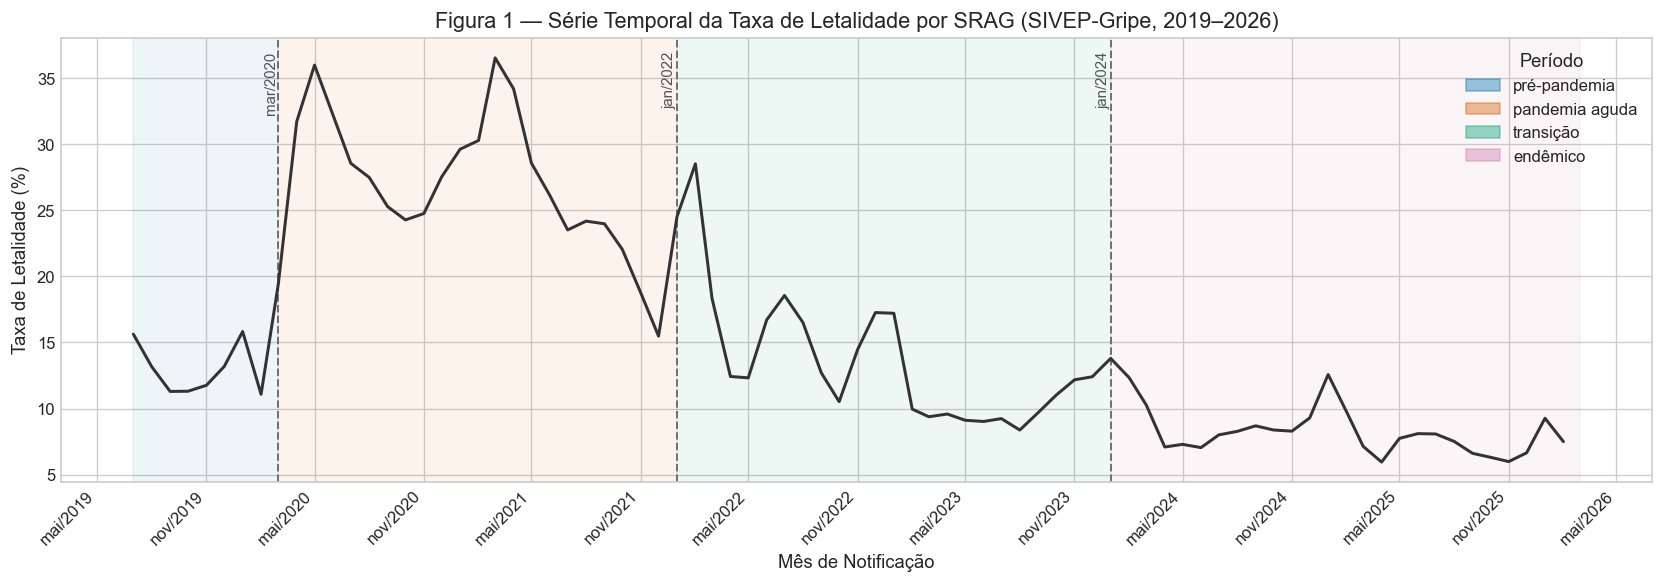

Salvo: C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\fig1_letalidade_temporal.png


In [4]:
# Agrupamento mensal: count() ignora NaN → conta só desfechos definidos (EVOLUCAO 1 ou 2)
monthly = (
    df.groupby('ano_mes')['obito']
    .agg(casos='count', obitos='sum')
    .reset_index()
)
monthly['letalidade'] = monthly['obitos'] / monthly['casos']
monthly['dt'] = monthly['ano_mes'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(14, 5))
add_period_spans(ax)
ax.plot(monthly['dt'], monthly['letalidade'] * 100,
        color='#333333', linewidth=1.8, zorder=3)
add_vlines(ax)
fmt_xaxis(ax)

ax.set_ylabel('Taxa de Letalidade (%)')
ax.set_xlabel('Mês de Notificação')
ax.set_title('Figura 1 — Série Temporal da Taxa de Letalidade por SRAG (SIVEP-Gripe, 2019–2026)')

# Legenda manual de períodos
handles = [plt.Rectangle((0,0),1,1, color=PERIOD_COLORS[p], alpha=0.4)
           for p in PERIOD_ORDER]
ax.legend(handles, PERIOD_ORDER, loc='upper right', title='Período', framealpha=0.9)

plt.tight_layout()
out1 = FIG_DIR / 'fig1_letalidade_temporal.png'
plt.savefig(out1, dpi=120, bbox_inches='tight')
plt.show()
print(f'Salvo: {out1}')


## Seção 4: Figura 2 — Série Temporal da Idade Mediana dos Óbitos

Analisamos a evolução da distribuição etária entre os óbitos ao longo do tempo. A banda sombreada representa o intervalo interquartil (P25–P75), capturando a dispersão além da mediana.


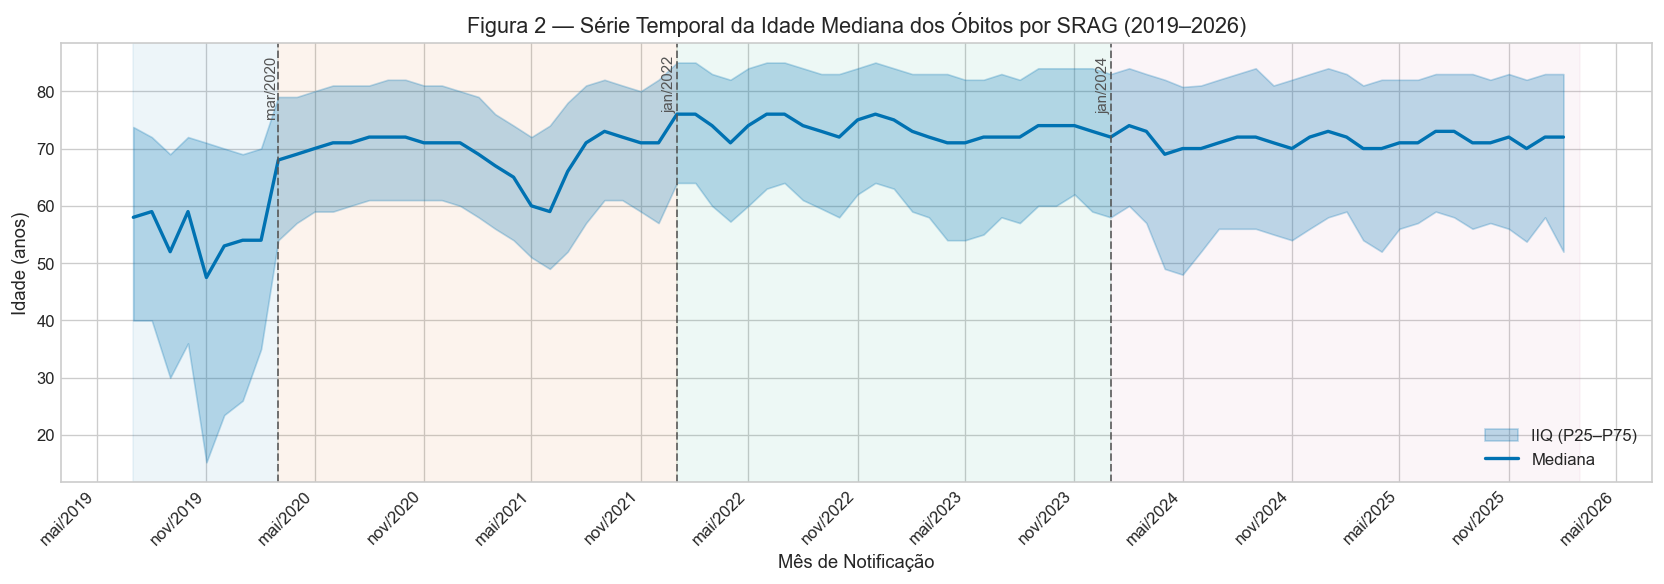

Salvo: C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\fig2_idade_obitos_temporal.png


In [5]:
df_obitos = df[df['obito'] == True].copy()

age_monthly = (
    df_obitos.groupby('ano_mes')['idade']
    .describe(percentiles=[0.25, 0.5, 0.75])
    [['25%', '50%', '75%']]
    .rename(columns={'25%': 'p25', '50%': 'mediana', '75%': 'p75'})
    .reset_index()
)
age_monthly['dt'] = age_monthly['ano_mes'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(14, 5))
add_period_spans(ax)

ax.fill_between(age_monthly['dt'], age_monthly['p25'], age_monthly['p75'],
                alpha=0.25, color='#0072B2', label='IIQ (P25–P75)')
ax.plot(age_monthly['dt'], age_monthly['mediana'],
        color='#0072B2', linewidth=2, label='Mediana')

add_vlines(ax)
fmt_xaxis(ax)

ax.set_ylabel('Idade (anos)')
ax.set_xlabel('Mês de Notificação')
ax.set_title('Figura 2 — Série Temporal da Idade Mediana dos Óbitos por SRAG (2019–2026)')
ax.legend(loc='lower right', framealpha=0.9)

plt.tight_layout()
out2 = FIG_DIR / 'fig2_idade_obitos_temporal.png'
plt.savefig(out2, dpi=120, bbox_inches='tight')
plt.show()
print(f'Salvo: {out2}')


## Seção 5: Figura 3 — CDFs de Idade por Período

A Função de Distribuição Acumulada Empírica (ECDF) permite comparar visualmente a distribuição etária dos casos entre os quatro períodos. Qualquer deslocamento horizontal sinaliza um distribution shift na variável `idade`.

A diferença máxima entre as CDFs pré-pandemia e pandemia aguda é uma prévia visual da estatística D do teste KS (a ser calculado no Dia 2 da análise).

Para eficiência com ~4M registros, amostramos até 100.000 por período.


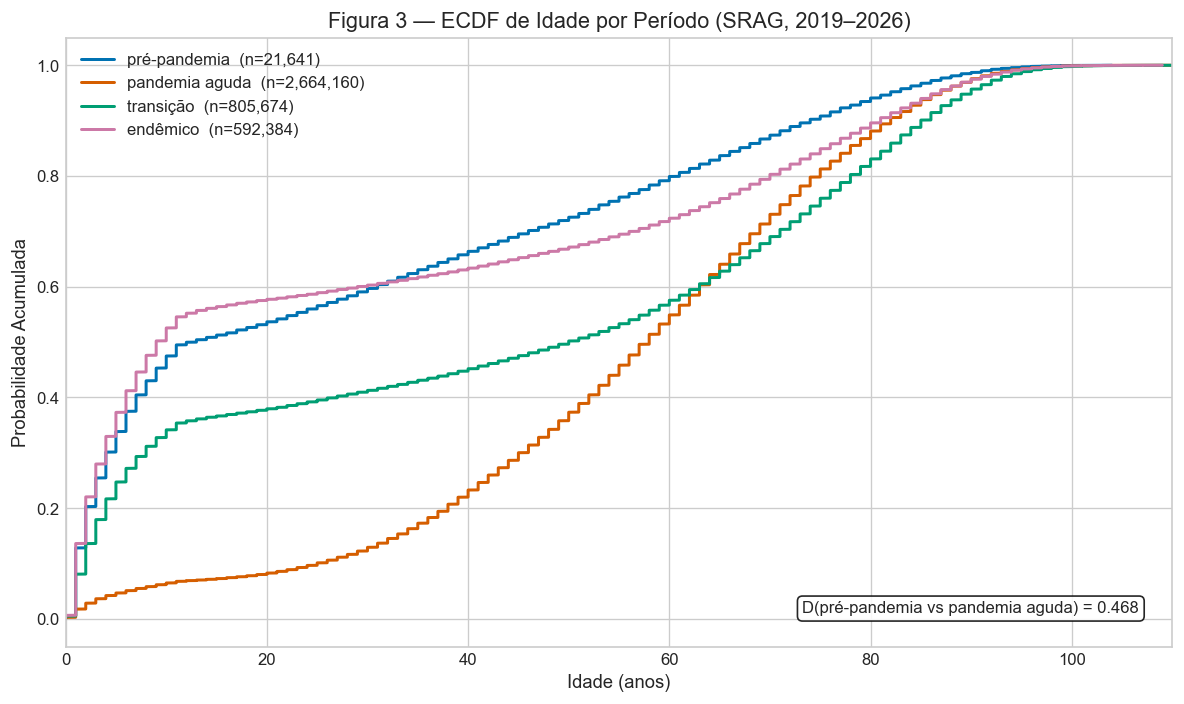

Salvo: C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\fig3_cdf_idade_periodos.png
Estatística D (KS pré vs pandemia): 0.4682


In [6]:
rng = np.random.default_rng(42)
MAX_SAMPLE = 100_000

fig, ax = plt.subplots(figsize=(10, 6))

ecdf_data = {}
for periodo in PERIOD_ORDER:
    subset = df[df['periodo'] == periodo]['idade'].dropna()
    n_orig = len(subset)
    if n_orig > MAX_SAMPLE:
        subset = subset.sample(MAX_SAMPLE, random_state=42)
    x = np.sort(subset.values)
    y = np.arange(1, len(x) + 1) / len(x)
    ecdf_data[periodo] = (x, y)
    ax.plot(x, y, label=f'{periodo}  (n={n_orig:,})',
            color=PERIOD_COLORS[periodo], linewidth=1.8)

# Estatística D entre pré-pandemia e pandemia aguda
x1, y1 = ecdf_data['pré-pandemia']
x2, y2 = ecdf_data['pandemia aguda']
x_grid = np.linspace(0, 110, 2000)
cy1 = np.interp(x_grid, x1, y1, left=0, right=1)
cy2 = np.interp(x_grid, x2, y2, left=0, right=1)
ks_d = float(np.max(np.abs(cy1 - cy2)))

ax.text(0.97, 0.05,
        f'D(pré-pandemia vs pandemia aguda) = {ks_d:.3f}',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=10,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

ax.set_xlabel('Idade (anos)')
ax.set_ylabel('Probabilidade Acumulada')
ax.set_title('Figura 3 — ECDF de Idade por Período (SRAG, 2019–2026)')
ax.set_xlim(0, 110)
ax.legend(loc='upper left', framealpha=0.9)

plt.tight_layout()
out3 = FIG_DIR / 'fig3_cdf_idade_periodos.png'
plt.savefig(out3, dpi=120, bbox_inches='tight')
plt.show()
print(f'Salvo: {out3}')
print(f'Estatística D (KS pré vs pandemia): {ks_d:.4f}')


## Seção 6: Tabela Descritiva Comparativa

Consolidamos as principais estatísticas de cada período em um único DataFrame: volume, letalidade, distribuição etária e composição demográfica (sexo e raça/cor). Essa tabela alimenta diretamente a seção de resultados da dissertação.


In [9]:
rows = []
for periodo in PERIOD_ORDER:
    sub = df[df['periodo'] == periodo]
    n_total    = len(sub)
    n_definido = int(sub['obito'].notna().sum())
    n_obitos   = int(sub['obito'].sum())
    letalidade = n_obitos / n_definido * 100 if n_definido > 0 else np.nan

    idade_media   = sub['idade'].mean()
    idade_mediana = sub['idade'].median()
    idade_std     = sub['idade'].std()

    idade_med_ob  = sub.loc[sub['obito'] == True,  'idade'].median()
    idade_med_nob = sub.loc[sub['obito'] == False, 'idade'].median()

    sexo = sub['CS_SEXO'].value_counts(normalize=True) * 100
    raca = sub['raca'].value_counts(normalize=True) * 100

    row = {
        'N Total':                    n_total,
        'N Desfecho Definido':        n_definido,
        'N Óbitos':                   n_obitos,
        'Letalidade (%)':             round(letalidade, 1),
        'Idade Média':                round(idade_media, 1),
        'Idade Mediana':              round(idade_mediana, 1),
        'Idade DP':                   round(idade_std, 1),
        'Idade Mediana Óbitos':       round(idade_med_ob, 1),
        'Idade Mediana Não-Óbitos':   round(idade_med_nob, 1),
        'Sexo M (%)':                 round(sexo.get('M', 0), 1),
        'Sexo F (%)':                 round(sexo.get('F', 0), 1),
        'Sexo Ignorado (%)':          round(sexo.get('I', 0), 1),
    }
    for r in ['Branca','Preta','Amarela','Parda','Indígena','Ignorado']:
        row[f'Raça {r} (%)'] = round(raca.get(r, 0.0), 1)
    rows.append({'Período': periodo, **row})

tabela = pd.DataFrame(rows).set_index('Período')
csv_path = TABLE_DIR / 'tabela_descritiva_periodos.csv'
tabela.to_csv(csv_path)
print(f'Salvo: {csv_path}')
tabela.T


Salvo: C:\master-degree-fairness-distribution_shifts\src\notebooks\tables\tabela_descritiva_periodos.csv


Período,pré-pandemia,pandemia aguda,transição,endêmico
N Total,21641.0,2664250.0,805720.0,592407.0
N Desfecho Definido,20857.0,2558566.0,761815.0,562768.0
N Óbitos,2755.0,738827.0,124561.0,45424.0
Letalidade (%),13.2,28.9,16.4,8.1
Idade Média,28.7,55.1,43.3,30.4
Idade Mediana,13.0,58.0,50.0,9.0
Idade DP,28.9,22.3,33.6,32.6
Idade Mediana Óbitos,57.0,68.0,75.0,71.0
Idade Mediana Não-Óbitos,10.0,53.0,31.0,8.0
Sexo M (%),51.1,54.5,50.9,51.6


## Seção 7: Letalidade por Raça/Cor ao Longo do Tempo

Esta figura é central para o argumento de **fairness** da dissertação: mostra se a pandemia afetou desproporcionalmente grupos raciais específicos. A média móvel de 3 meses suaviza a volatilidade mês-a-mês preservando tendências.


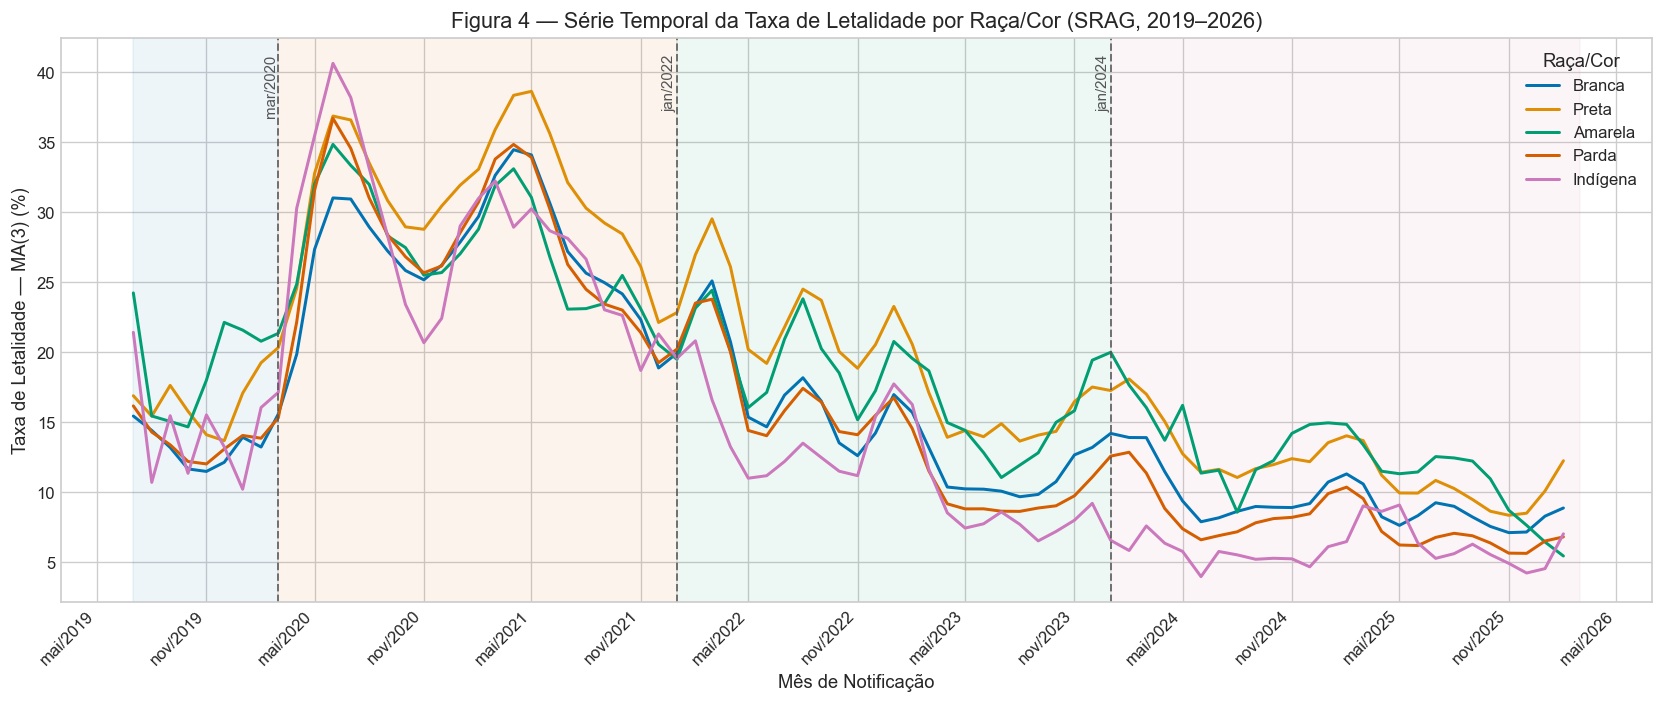

Salvo: C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\fig4_letalidade_por_raca.png


In [10]:
RACAS_PLOT  = ['Branca', 'Preta', 'Amarela', 'Parda', 'Indígena']
RACA_COLORS = dict(zip(RACAS_PLOT,
                       sns.color_palette('colorblind', len(RACAS_PLOT))))

df_raca = df[df['obito'].notna() & df['raca'].isin(RACAS_PLOT)].copy()

monthly_raca = (
    df_raca.groupby(['ano_mes', 'raca'], observed=True)['obito']
    .agg(casos='count', obitos='sum')
    .reset_index()
)
monthly_raca['letalidade'] = monthly_raca['obitos'] / monthly_raca['casos']
monthly_raca['dt'] = monthly_raca['ano_mes'].dt.to_timestamp()

pivot  = monthly_raca.pivot(index='dt', columns='raca', values='letalidade')
smooth = pivot.rolling(3, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(14, 6))
add_period_spans(ax)

for raca in RACAS_PLOT:
    if raca in smooth.columns:
        ax.plot(smooth.index, smooth[raca] * 100,
                label=raca, color=RACA_COLORS[raca], linewidth=1.8)

add_vlines(ax)
fmt_xaxis(ax)

ax.set_ylabel('Taxa de Letalidade — MA(3) (%)')
ax.set_xlabel('Mês de Notificação')
ax.set_title('Figura 4 — Série Temporal da Taxa de Letalidade por Raça/Cor (SRAG, 2019–2026)')
ax.legend(loc='upper right', title='Raça/Cor', framealpha=0.9)

plt.tight_layout()
out4 = FIG_DIR / 'fig4_letalidade_por_raca.png'
plt.savefig(out4, dpi=120, bbox_inches='tight')
plt.show()
print(f'Salvo: {out4}')
